# ML Network Intrusion Detector
**IBM SkillsBuild Cyber Security 2026 (BharatCares) – Capstone Project**

**Author:** Arjun Pundir

This notebook builds a machine-learning model with Scikit-learn that classifies network connections as **normal** or **attack** (and into attack families) using the public **NSL-KDD** dataset.

**Pipeline:** load data → explore → preprocess → train models → evaluate on a separate test set → interpret → save model.

## 1. Setup

In [1]:
import os, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 2. Load the NSL-KDD dataset
NSL-KDD is an improved version of KDD'99 with duplicate records removed. `KDDTrain+` is used for training and `KDDTest+` (which contains attack types not seen in training) is used for testing, which gives a more realistic estimate of performance.

Source: https://github.com/defcom17/NSL_KDD (mirror of the Canadian Institute for Cybersecurity dataset: https://www.unb.ca/cic/datasets/nsl.html)

In [2]:
BASE = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/"
FILES = {"train": "KDDTrain%2B.txt", "test": "KDDTest%2B.txt"}

def fetch(name, url_name):
    local = f"{name}.csv"
    if not os.path.exists(local):
        print(f"Downloading {name} set...")
        urllib.request.urlretrieve(BASE + url_name, local)
    return local

columns = ["duration","protocol_type","service","flag","src_bytes","dst_bytes","land","wrong_fragment",
 "urgent","hot","num_failed_logins","logged_in","num_compromised","root_shell","su_attempted","num_root",
 "num_file_creations","num_shells","num_access_files","num_outbound_cmds","is_host_login","is_guest_login",
 "count","srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate","same_srv_rate",
 "diff_srv_rate","srv_diff_host_rate","dst_host_count","dst_host_srv_count","dst_host_same_srv_rate",
 "dst_host_diff_srv_rate","dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",
 "dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate","label","difficulty"]

train = pd.read_csv(fetch("train", FILES["train"]), names=columns)
test  = pd.read_csv(fetch("test",  FILES["test"]),  names=columns)
print("Train:", train.shape, "| Test:", test.shape)
train.head()

Train: (125973, 43) | Test: (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


## 3. Exploratory data analysis

In [3]:
print("Missing values (train):", int(train.isna().sum().sum()))
print("Duplicate rows (train):", int(train.duplicated().sum()))
train.drop(columns="difficulty").describe().T.head(10)

Missing values (train): 0


Duplicate rows (train): 0


,count,mean,std,min,25%,50%,75%,max
duration,125973.0,287.144650,2.604515e+03,0.0,0.0,0.0,0.0,4.290800e+04
src_bytes,125973.0,45566.743000,5.870331e+06,0.0,0.0,44.0,276.0,1.379964e+09
dst_bytes,125973.0,19779.114421,4.021269e+06,0.0,0.0,0.0,516.0,1.309937e+09
land,125973.0,0.000198,1.408607e-02,0.0,0.0,0.0,0.0,1.000000e+00
wrong_fragment,125973.0,0.022687,2.535300e-01,0.0,0.0,0.0,0.0,3.000000e+00
urgent,125973.0,0.000111,1.436603e-02,0.0,0.0,0.0,0.0,3.000000e+00
hot,125973.0,0.204409,2.149968e+00,0.0,0.0,0.0,0.0,7.700000e+01
num_failed_logins,125973.0,0.001222,4.523914e-02,0.0,0.0,0.0,0.0,5.000000e+00
logged_in,125973.0,0.395736,4.890101e-01,0.0,0.0,0.0,1.0,1.000000e+00
num_compromised,125973.0,0.279250,2.394204e+01,0.0,0.0,0.0,0.0,7.479000e+03


### 3.1 Label mapping
The raw dataset has ~40 specific attack names. They are grouped into the standard four attack families (**DoS, Probe, R2L, U2R**) plus **normal**. A binary label (`normal` vs `attack`) is also derived.

In [4]:
attack_map = {"normal":"normal"}
for a in ["back","land","neptune","pod","smurf","teardrop","apache2","udpstorm","processtable","mailbomb","worm"]:
    attack_map[a] = "DoS"
for a in ["satan","ipsweep","nmap","portsweep","mscan","saint"]:
    attack_map[a] = "Probe"
for a in ["guess_passwd","ftp_write","imap","phf","multihop","warezmaster","warezclient","spy",
          "xlock","xsnoop","snmpguess","snmpgetattack","httptunnel","sendmail","named"]:
    attack_map[a] = "R2L"
for a in ["buffer_overflow","loadmodule","rootkit","perl","sqlattack","xterm","ps"]:
    attack_map[a] = "U2R"

for df in (train, test):
    df["category"] = df["label"].map(attack_map)
    df["is_attack"] = (df["label"] != "normal").astype(int)

print("Unmapped labels:", set(train.label) - set(attack_map), set(test.label) - set(attack_map))
print(train["category"].value_counts())

Unmapped labels: set() set()
category
normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64


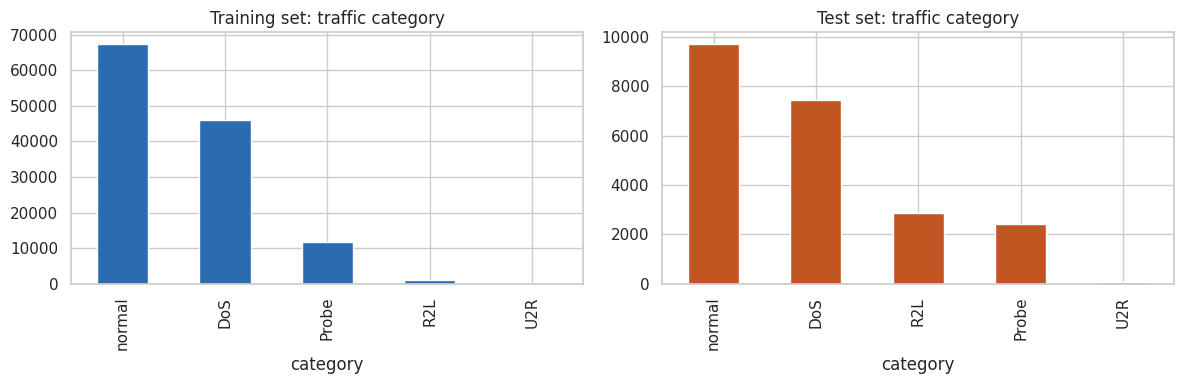

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
train["category"].value_counts().plot.bar(ax=ax[0], color="#2b6cb0"); ax[0].set_title("Training set: traffic category")
test["category"].value_counts().plot.bar(ax=ax[1], color="#c05621");  ax[1].set_title("Test set: traffic category")
plt.tight_layout(); plt.show()

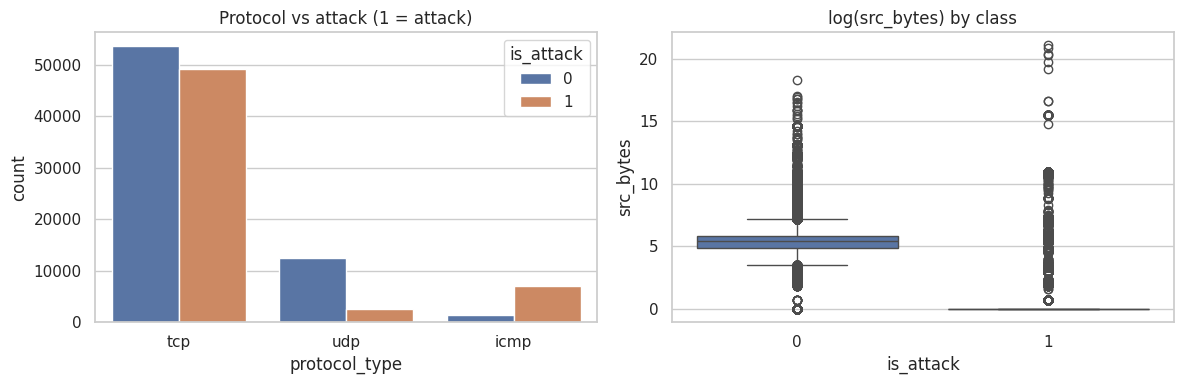

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=train, x="protocol_type", hue="is_attack", ax=ax[0]); ax[0].set_title("Protocol vs attack (1 = attack)")
sns.boxplot(data=train, x="is_attack", y=np.log1p(train["src_bytes"]), ax=ax[1]); ax[1].set_title("log(src_bytes) by class")
plt.tight_layout(); plt.show()

## 4. Preprocessing
Categorical columns (`protocol_type`, `service`, `flag`) are one-hot encoded and numeric columns are standardised. Everything is inside a Scikit-learn `Pipeline`, so the test set is transformed with parameters learned only from the training data (no leakage).

In [7]:
cat_cols = ["protocol_type", "service", "flag"]
drop_cols = ["label", "category", "is_attack", "difficulty"]
num_cols = [c for c in train.columns if c not in cat_cols + drop_cols]

X_train, X_test = train.drop(columns=drop_cols), test.drop(columns=drop_cols)
y_train_bin, y_test_bin = train["is_attack"], test["is_attack"]
y_train_cat, y_test_cat = train["category"], test["category"]

def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])
print(len(num_cols), "numeric features,", len(cat_cols), "categorical features")

38 numeric features, 3 categorical features


## 5. Binary classification: normal vs attack
Three models of increasing complexity are compared.

In [8]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree":       DecisionTreeClassifier(max_depth=15, random_state=RANDOM_STATE),
    "Random Forest":       RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE),
}
fitted, rows = {}, []
for name, clf in models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", clf)]).fit(X_train, y_train_bin)
    pred = pipe.predict(X_test)
    fitted[name] = pipe
    rows.append({"Model": name,
                 "Accuracy":  accuracy_score(y_test_bin, pred),
                 "Precision": precision_score(y_test_bin, pred),
                 "Recall":    recall_score(y_test_bin, pred),
                 "F1":        f1_score(y_test_bin, pred)})
results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.7537,0.9174,0.6234,0.7424
Decision Tree,0.7831,0.9583,0.6471,0.7725
Random Forest,0.7677,0.9676,0.6123,0.7500


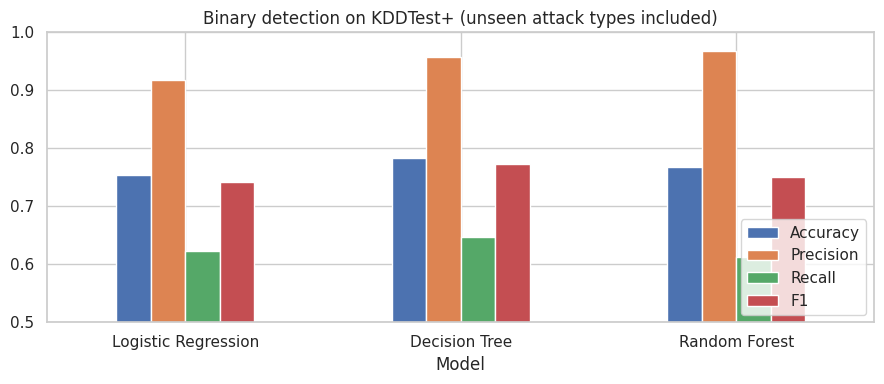

In [9]:
results.plot.bar(figsize=(9, 4), ylim=(0.5, 1.0), rot=0)
plt.title("Binary detection on KDDTest+ (unseen attack types included)")
plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

### 5.0 Generalisation check
5-fold cross-validation on the training file is compared with the score on `KDDTest+`. A large gap shows the models struggle with attack variants they have not seen.

In [10]:
from sklearn.model_selection import cross_val_score
gap = []
for name, clf in models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", clf)])
    cv = cross_val_score(pipe, X_train, y_train_bin, cv=5, scoring="f1", n_jobs=-1).mean()
    gap.append({"Model": name, "CV F1 (train file)": cv, "Test F1 (KDDTest+)": results.loc[name, "F1"]})
gap = pd.DataFrame(gap).set_index("Model").round(4)
gap

,CV F1 (train file),Test F1 (KDDTest+)
Model,,
Logistic Regression,0.9707,0.7424
Decision Tree,0.9980,0.7725
Random Forest,0.9989,0.7500


### 5.1 Confusion matrix and report for the best model

Best model: Decision Tree
              precision    recall  f1-score   support

      normal     0.6737    0.9628    0.7927      9711
      attack     0.9583    0.6471    0.7725     12833

    accuracy                         0.7831     22544
   macro avg     0.8160    0.8050    0.7826     22544
weighted avg     0.8357    0.7831    0.7812     22544



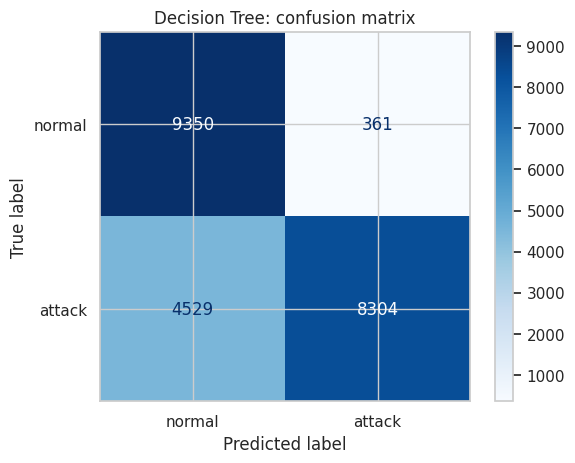

False positive rate: 3.72% | False negative (missed attack) rate: 35.29%


In [11]:
best_name = results["F1"].idxmax()
best = fitted[best_name]
pred = best.predict(X_test)
print("Best model:", best_name)
print(classification_report(y_test_bin, pred, target_names=["normal", "attack"], digits=4))
ConfusionMatrixDisplay(confusion_matrix(y_test_bin, pred), display_labels=["normal", "attack"]).plot(cmap="Blues")
plt.title(f"{best_name}: confusion matrix"); plt.show()
tn, fp, fn, tp = confusion_matrix(y_test_bin, pred).ravel()
print(f"False positive rate: {fp/(fp+tn):.2%} | False negative (missed attack) rate: {fn/(fn+tp):.2%}")

## 6. Multi-class classification: attack families
Next the model predicts the *type* of traffic (normal, DoS, Probe, R2L, U2R). R2L and U2R are rare, and the test set contains attack variants absent from training, so these are the hardest classes.

Accuracy: 0.7531
              precision    recall  f1-score   support

      normal     0.6533    0.9738    0.7820      9711
         DoS     0.9628    0.7971    0.8721      7460
       Probe     0.8242    0.6043    0.6973      2421
         R2L     0.9737    0.0385    0.0740      2885
         U2R     0.3333    0.0149    0.0286        67

    accuracy                         0.7531     22544
   macro avg     0.7495    0.4857    0.4908     22544
weighted avg     0.8141    0.7531    0.7099     22544



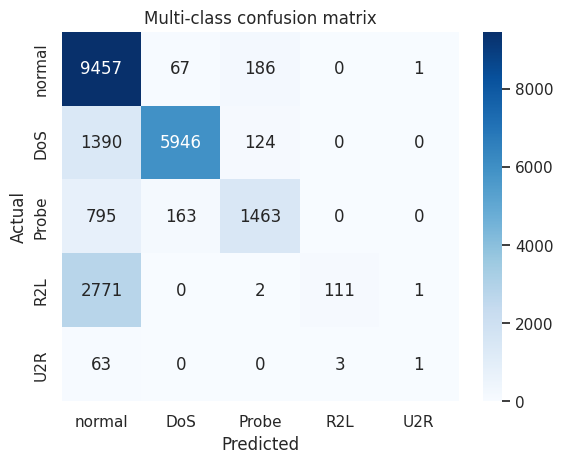

In [12]:
multi = Pipeline([("prep", make_preprocessor()),
                  ("clf", RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE))])
multi.fit(X_train, y_train_cat)
pred_cat = multi.predict(X_test)
labels = ["normal", "DoS", "Probe", "R2L", "U2R"]
print("Accuracy:", round(accuracy_score(y_test_cat, pred_cat), 4))
print(classification_report(y_test_cat, pred_cat, labels=labels, digits=4, zero_division=0))
cm = confusion_matrix(y_test_cat, pred_cat, labels=labels)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Multi-class confusion matrix"); plt.show()

## 7. Feature importance
Which traffic characteristics drive the Random Forest's decisions?

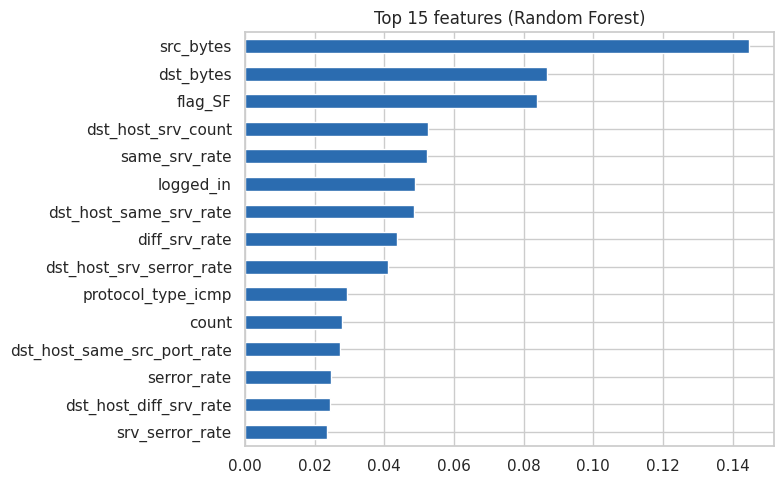

In [13]:
rf = fitted["Random Forest"]
names = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=names).sort_values(ascending=False).head(15)
imp.index = [i.split("__")[1] for i in imp.index]
imp[::-1].plot.barh(figsize=(8, 5), color="#2b6cb0")
plt.title("Top 15 features (Random Forest)"); plt.tight_layout(); plt.show()

## 8. Save the model
The full pipeline (preprocessing + classifier) is stored so it can score new connection records directly.

In [14]:
joblib.dump(fitted[best_name], "intrusion_detector_model.joblib")
loaded = joblib.load("intrusion_detector_model.joblib")
sample = X_test.sample(5, random_state=RANDOM_STATE)
print(pd.DataFrame({"predicted": np.where(loaded.predict(sample) == 1, "attack", "normal"),
                    "actual": test.loc[sample.index, "label"].values}, index=sample.index))

      predicted   actual
6186     normal   normal
247      attack  neptune
4343     normal   normal
17527    normal   normal
13123    normal   normal


## 9. Conclusions and limitations
* All three models reach 75-78% accuracy on `KDDTest+`. Precision for the attack class is high (92-97%) so alerts are trustworthy, but recall is only 61-65%, meaning roughly one in three attacks is missed. For a security tool, that is the key weakness.
* The simple Decision Tree scored best on F1 here, ahead of Random Forest and Logistic Regression. The gap between models is small compared with the gap between cross-validation and test scores (section 5.0), so the main challenge is **generalising to unseen attacks**, not model choice.
* DoS attacks are detected well, Probe moderately, while **R2L and U2R are almost never caught** (recall below 5%) because they have few training examples and the test set contains new variants.
* NSL-KDD is dated (derived from 1999 traffic) and its test set is intentionally difficult, so these numbers should not be read as production performance.

**Possible improvements:** class weighting or SMOTE for rare classes, lowering the decision threshold to trade precision for recall, hyper-parameter tuning, gradient boosting, and retraining on modern data such as CIC-IDS2017/2018.